In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [3]:
from Experiment_4.ParametricWMTask import generate_trials
import pandas as pd
import matplotlib
import torch
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from Experiment_4.net import *
import os
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .75

In [4]:
def compute_var(variance,n):
    return np.sum(variance[n:])

def compute_p(k, null_k):
    return (np.sum(null_k<k)/len(null_k))

In [5]:
df_list = []
for filename in os.listdir('Experiment_1/Results_1'):
    f = os.path.join('Experiment_1/Results_1', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True)

In [6]:
15*15*3

675

1.0


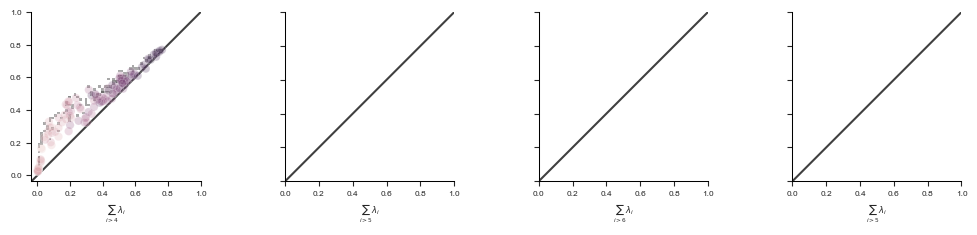

In [7]:
# PLOT VARIANCE VS INERTIA
import scipy.optimize as opt
import math
fig = plt.figure(figsize=(12,3))
gs = gridspec.GridSpec(1,4,wspace = .5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])
axes = [ax0,ax1,ax2,ax3]

df_list = []
for filename in os.listdir('Experiment_1/Results_1'):
    f = os.path.join('Experiment_1/Results_1', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True) 
#original_df.activity_std = original_df.activity_std.astype(float)
#original_df = original_df[original_df.lambda_curve.isin([0,2])]
original_df = original_df[original_df.mse_z<.035]
##original_df_act = original_df_act[original_df_act.sigma_rec==0]
#original_df_act = original_df_act[original_df_act.lr==0.005]
original_df = original_df[original_df.n==100]
#original_df_act = original_df_act[original_df_act.beta==1.4]
#original_df.lvar = original_df.lvar.astype(float)
#original_df = original_df[original_df.lvar>0]
#original_df_act = original_df_act[original_df_act.beta==5.]


#original_df = original_df[original_df.k>1]
parameters = []
fit_rows = []

for i in range(1):
    ax = axes[i]
    k = i+3
    df = original_df.copy()
    # df['var'] = df.variance.apply(lambda x: compute_var(x,k))
    # df['var_pre'] = df.variance.apply(lambda x: compute_var(x,k-1))
    # df['k_inertia'] = df.inertia.apply(lambda x: x[k-1])
    #df = df[df['var_pre']>.25]
    #df['error'] = df['kmeans_error']*df['linear_error']
    #df = df[df.k>=k]
    df = df[df.dim==k]
    #df = df[df.lvar>0]
    #df['pca_error'] = np.log(df['pca_error'])
    print(df.lvar.max())
    #df = df[df['var']<-.35]
    
        # Construct null dataframe
    rows = []
    for index, row in df.iterrows():
        rows.append({'model_id':row['model_id'],
                     'pca_error':row['pca_error'],
        'kmeans_error': row['null_kmeans_error']})
    null_df = pd.DataFrame(rows)     
   # null_df = null_df.groupby(['model_id']).mean().reset_index()
   #sns.histplot(data=df, x='pca_error',y='kmeans_error',ax=ax,legend=True,alpha=1,bins=(55,55),hue = 'lambda_curve')
    sns.histplot(data=null_df, x='pca_error',y='kmeans_error',ax=ax,legend=False,alpha=1,bins=(45,45),color='gray')
    sns.scatterplot(data=df, x='pca_error',y='kmeans_error',ax=ax,legend=False,alpha=.25,hue = 'linear_error')


    # def f(x, a,b,c,d):
    #     #return a + c * np.log(1 + np.exp(b * (x-d))) / b
    #     #return a + c*np.log(1+np.exp(20 * (x-b)))/20
    #     return  a + b/(1+np.exp(c*(x-d)))
    # # bounds = ([0,0,-np.inf,-np.inf],
    # #               [np.inf, np.inf,0,0])
    # bounds = ([0,0,-np.inf,-np.inf],
    #               [np.inf, np.inf,0,0])
    # x_values = np.linspace(df['var'].min(),df['var'].max(),20)
    # #for lr in [0.001, 0.005]:
    # for sample in range(100):   
    #     #try:
    #     frac = .1
    #     sample_df = df.sample(frac=frac)
    #     x = sample_df['var'].values.astype(float)
    #     y = sample_df.k_inertia.values
    # 
    #     sample_null_df = null_df.sample(frac=frac)
    #     x_null = sample_null_df['var'].values.astype(float)
    #     y_null = sample_null_df.inertia.values
    # 
    #     try:
    #         popt, pcov = opt.curve_fit(f, x, y, method="trf",max_nfev=10000,bounds = bounds)
    #         #popt, pcov = opt.curve_fit(f, x, y, method="trf",max_nfev=10000)
    #         y_fit = f(x_values, *popt)
    # 
    #         for step in range(20):
    #             fit_rows.append({'sample':sample,
    #                              'step': step,
    #                              'k':k,
    #                          'type': 1,
    #                          'x':x_values[step],
    #                          'y': y_fit[step],
    #                          'a':popt[0]})
    #     except:
    #         continue
    # 
    # 
    #     try:
    #         popt, pcov = opt.curve_fit(f, x_null, y_null, method="trf",max_nfev=10000,bounds = bounds)
    #         y_fit = f(x_values, *popt)
    #         for step in range(20):
    #             fit_rows.append({'sample':sample,
    #                              'step':step,
    #                              'k':k,
    #                          'type': 0,
    #                          'x':x_values[step],
    #                          'y': y_fit[step],
    #                          'a':popt[0]})
    #     except:
    #        continue
    # 


# fit_df = pd.DataFrame(fit_rows)
# for k in range(3):
#     ax = axes[k]
#     sns.lineplot(data = fit_df[(fit_df.type==1) & (fit_df.k==k+2)], x= 'x', y='y',ax=ax,legend = False,lw=.5,color='tab:blue',alpha = 1,errorbar=None, linestyle='--')
#     sns.lineplot(data = fit_df[(fit_df.type==0)& (fit_df.k==k+2)], x= 'x', y='y',ax=ax,legend = False,lw=.5,color='gray',linestyle='--',alpha= .25, errorbar = None)

for ax in [ax0,ax1,ax2,ax3]:
#     
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_ylabel('', fontsize=8)
    ax.xaxis.set_tick_params(labelsize=6,bottom=True)
    ax.yaxis.set_tick_params(labelsize=6,left=True)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
   # plt.yticks(list(plt.yticks()[0]) + [5.0])
    ax.set_ylim(0,1)
    lims = [
        np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
        np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
    ]

    # now plot both limits against eachother
    ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0)
    ax.set_aspect('equal')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    # ax.set_xlim(-.1,1)
ax1.set_yticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])


ax0.set_xlabel( r"$\sum_{i>4}\lambda_i$", fontsize=6)
ax1.set_xlabel(r"$\sum_{i>5}\lambda_i$", fontsize=6)
ax2.set_xlabel(r"$\sum_{i>6}\lambda_i$", fontsize=6)
ax3.set_xlabel(r"$\sum_{i>5}\lambda_i$", fontsize=6)
fig.savefig('Figures/Figure_2_a.jpg',
    format='jpeg',
    dpi=450,
    bbox_inches='tight'

            )

In [10]:
df

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,n,lvar,dim,null_kmeans_error,pca_error,kmeans_error,linear_error,kmeans_lambda,pca_lambda,linear_lambda
21,7pMSGWZP,"[[0.0, -0.07785827, 0.0078497715, 0.0003672538...","[[-0.056093756, 0.14228725], [0.19143134, -0.2...","[[0.058869217, 0.13822265, 0.1299886, 0.219373...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.028824,1000,0.0,0.0,0.001,...,100,1.0,3,0.156225,0.019889,0.094454,0.191816,0.0,0.0,0.0
22,2SVndCX8,"[[0.0, 0.038174767, -0.058277633, 0.032967318,...","[[0.0372973, -0.18208927], [0.026850782, -0.17...","[[-0.09332092, 0.02652405, 0.113652475, 0.0046...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.033493,1000,0.0,0.0,0.001,...,100,1.0,3,0.383852,0.122429,0.353246,0.246961,0.0,0.0,1.0
23,iqL6HZbE,"[[0.0, -0.07743957, 0.034795377, 0.016117504, ...","[[-0.020468773, -0.07234197], [0.037456788, 0....","[[0.15816642, 0.14600316, 0.169217, 0.21698117...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.001212,1000,0.0,0.0,0.001,...,100,1.0,3,0.409547,0.191428,0.363654,0.318391,0.0,0.0,10.0
25,5cVHiNLX,"[[0.0, -0.07300781, -0.051582277, -0.029164126...","[[-0.0057472847, 0.033584926], [0.23186482, 0....","[[0.11095364, -0.036447074, 0.29700312, 0.1259...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.003421,1000,0.0,0.0,0.001,...,100,1.0,3,0.656218,0.567890,0.646512,0.665461,0.0,1.0,0.0
37,tn9gSPmL,"[[0.0, -0.14321177, 0.0022452155, 0.0051936726...","[[0.16103113, 0.1792165], [-0.06895843, -0.117...","[[0.14685102, -0.087734245, 0.11088927, 0.0810...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.000838,1000,0.0,0.0,0.001,...,100,1.0,3,0.429400,0.085605,0.422738,0.197389,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63993,dDz6fpBn,"[[0.0, -0.030898454, 0.009240465, -0.11818719,...","[[0.22596456, -0.047969073], [0.061308686, 0.0...","[[0.10467507, 0.05681159, 0.08507549, -0.03080...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.002347,1000,0.0,0.0,0.001,...,100,1.0,3,0.571432,0.410942,0.570255,0.557496,10.0,1.0,0.0
63994,I3iTzq8M,"[[0.0, -0.05741743, -0.14413908, -0.023945466,...","[[-0.0030126637, 0.1272353], [0.391222, -0.371...","[[0.10242806, 0.20745343, 0.06919169, 0.012584...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.001326,1000,0.0,0.0,0.001,...,100,1.0,3,0.552456,0.380429,0.553066,0.679225,10.0,1.0,1.0
63995,k8tTuDCP,"[[0.0, -0.18792015, 0.07416185, 0.025244907, -...","[[0.051083364, 0.09377728], [0.072103485, 0.03...","[[-0.009124141, -0.42162818, 0.12087098, 0.205...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.002025,1000,0.0,0.0,0.001,...,100,1.0,3,0.569056,0.358185,0.552548,0.514264,10.0,1.0,10.0
63997,uzwYhP4O,"[[0.0, 0.07035287, -0.051843923, -0.0035963638...","[[0.03701861, 0.05035127], [0.02514815, -0.029...","[[0.12921324, 0.10378638, -0.29991415, 0.11222...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.007100,1000,0.0,0.0,0.001,...,100,1.0,3,0.568541,0.444243,0.559537,0.564954,10.0,10.0,0.0


In [ ]:
original_df.lambda_curve.max()

In [ ]:
df

In [ ]:
367/24

In [12]:
k = 3
df = original_df.copy()
# df['var'] = df.variance.apply(lambda x: compute_var(x,k))
# df['var_pre'] = df.variance.apply(lambda x: compute_var(x,k-1))
# df['k_inertia'] = df.inertia.apply(lambda x: x[k-1])
df = df[df.dim==k]
df = df[df.linear_error>.4]
df.sort_values('pca_error', ascending=True)

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,n,lvar,dim,null_kmeans_error,pca_error,kmeans_error,linear_error,kmeans_lambda,pca_lambda,linear_lambda
50754,bkcJ8V89,"[[0.0, 0.0044716066, -0.035501964, -0.04083763...","[[-0.21805951, 0.12993518], [0.048142757, 0.01...","[[-0.116827674, 0.11923335, 0.10213599, 0.1058...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.002703,1000,0.0,0.0,0.001,...,100,1.0,3,0.177982,0.000083,0.008646,0.413650,-1.0,-1.0,1.0
57253,r6VkxPab,"[[0.0, -0.0026200577, 0.013829101, -0.0637115,...","[[-0.18999968, 0.14950056], [-0.17645295, 0.13...","[[0.03665114, -0.0037946005, 0.04697696, 0.138...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.003828,1000,0.0,0.0,0.001,...,100,1.0,3,0.070457,0.000694,0.015919,0.410854,1.0,0.0,0.0
37282,jQzyiU8s,"[[0.0, 0.005097389, -0.022900928, -0.026609393...","[[-0.056242157, 0.042621437], [0.091565005, -0...","[[-0.16927615, 0.0389636, -0.13005936, 0.21427...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.004845,1000,0.0,0.0,0.001,...,100,1.0,3,0.284062,0.050424,0.217964,0.724768,1.0,-1.0,1.0
6866,MTfV5np3,"[[0.0, 0.016651588, 0.028544886, 0.035466917, ...","[[-0.23935506, 0.059316486], [-0.07404839, -0....","[[-0.33997488, 0.11554698, 0.08846406, 0.14645...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.005656,1000,0.0,0.0,0.001,...,100,1.0,3,0.291989,0.067358,0.252041,0.464395,0.0,-1.0,1.0
2191,UjXnYteA,"[[0.0, -0.027257059, 0.04576206, -0.053585522,...","[[-0.011627853, 0.049534168], [-0.010783785, 0...","[[0.07059707, 0.16826256, -0.4521845, 0.154937...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.034921,1000,0.0,0.0,0.001,...,100,1.0,3,0.208391,0.070133,0.163086,0.470225,-1.0,10.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35822,svzbCbxg,"[[0.0, -0.08278091, 0.12070943, 0.080687955, -...","[[-0.00021438539, -0.03980429], [0.025768125, ...","[[0.41792026, -0.07570156, 0.084676035, 0.0958...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.005605,1000,0.0,0.0,0.001,...,100,1.0,3,0.737804,0.704037,0.719176,0.826948,1.0,10.0,1.0
2770,8Xxzmr9p,"[[0.0, 0.048581824, -0.083568305, 0.1208863, 0...","[[-0.0107166525, -0.027079785], [0.00969812, 0...","[[0.088789955, 0.18389426, 0.10725902, -0.0190...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.002323,1000,0.0,0.0,0.001,...,100,1.0,3,0.749678,0.706453,0.739585,0.779962,0.0,-1.0,1.0
20764,0Iul0prO,"[[0.0, -0.07278077, -0.16494106, -0.21039893, ...","[[0.37148878, 0.1898486], [-0.08158518, 0.0775...","[[0.14903823, -0.1106085, -0.0030329293, 0.242...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.003895,1000,0.0,0.0,0.001,...,100,1.0,3,0.734649,0.709673,0.735968,0.803265,0.0,10.0,-1.0
4831,tqs3KYNc,"[[0.0, -0.050952073, 0.20247574, -0.15081836, ...","[[-0.14738153, 0.38044187], [0.19895728, 0.174...","[[0.11055758, 0.11967149, -0.29184633, 0.25618...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",0.004421,1000,0.0,0.0,0.001,...,100,1.0,3,0.738110,0.719386,0.737777,0.795973,0.0,10.0,10.0


In [13]:
df = original_df.copy()
#net = torch.load('net.pth')
model_data = df[df.model_id=='bkcJ8V89']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
#net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
#net.output_layer.bias.data = torch.tensor(-0.2).float()
#net.activation = nn.Softplus(beta=torch.tensor(model_data['beta'].item()))
net.sigma_in = 0.
net.sigma_rec = 0.

u, z, mask, conditions  = generate_trials(
                            n_trials=25)

x = net(u).detach().cpu().numpy()

(100, 3750)


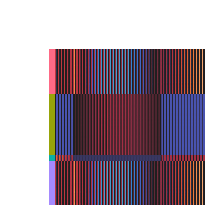

In [14]:
df = original_df.copy()
#net = torch.load('net.pth')
model_data = df[df.model_id=='bkcJ8V89']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
#net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
#net.output_layer.bias.data = torch.tensor(-0.2).float()
#net.activation = nn.Softplus(beta=torch.tensor(model_data['beta'].item()))
net.sigma_in = 0.
net.sigma_rec = 0.

u, z, mask, conditions  = generate_trials(
                            n_trials=25)

x = net(u).detach().cpu().numpy()


# Condition averages
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby('theta').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

# Remove outlier neurons
# z_scores = np.abs(stats.zscore(np.mean(x, axis=(0, 1))))
# good_indices = np.where(z_scores < 2)[0]
# responses = responses[good_indices,:]
#n_active = np.mean(responses, axis=1) > .025
n_active =np.mean(responses, axis=1) > .025
#lower_percentile = np.percentile(np.mean(responses, axis=1),5)
responses = responses[np.mean(responses, axis=1) > .025, :]

# Compute number of active units


# z_score
responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]



            
#_,k = compute_k(responses,5,25,.05)
#k = model_data.k.values[0]
k = 4
#print(k)
print(responses.shape)
clustering = KMeans(n_clusters=k,n_init=20).fit(responses)
labels  = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort,:]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)),row_cluster=False, col_cluster=False, row_colors=row_colors,figsize=(2.25,2.25),cbar_pos=None, xticklabels=False, yticklabels=False,center=0)
ax = g.ax_heatmap

g.savefig('Figures/Fig_2afc_b.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

In [10]:
df

,theta,response
0,0.000000,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
1,0.128228,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
2,0.256457,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
3,0.384685,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
4,0.512913,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
5,0.641141,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
6,0.769370,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
7,0.897598,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
8,1.025826,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
9,1.154054,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_62388/3885492217.py:39: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  H = w @ U


<Axes: xlabel='z_1', ylabel='z_2'>

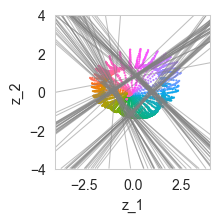

In [36]:

# HYPERPLANES
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1)
palette = sns.husl_palette(s=1,n_colors=50)

u, z, mask, conditions  = generate_trials(
                            n_trials=50)

ax=fig.add_subplot(gs[0,0])
model_data = original_df[original_df.model_id == 'gfLbVNJF']
net = Net(n=100,input_size = 2,dale=False,base_in=0.2)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2).float()
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2).float()
net.activation = torch.nn.Softplus(beta=model_data['beta'].item())
#net.sigma_in = 0.1
net.sigma_rec = 0

x = net.forward(u)
n_neurons = x.shape[2]
#Restrict to act
#  x = x[:,:,n_active]
pca = PCA()
pca.fit(x.detach().numpy().reshape(-1,x.shape[2]))

U = pca.components_[:6,:].T
#U = latent_net.module_.q[:2,:].t().detach()
w = net.recurrent_layer.weight.data
# w = w[n_active,:]
# w = w[:,n_active]
#w = w-np.eye(50)
w_in = net.input_layer.weight.data

b = net.recurrent_layer.bias.data

H = w @ U 
#H = H[sort,:]
proj_rates = pca.transform(x.detach().reshape(-1,x.shape[2]))
proj_rates = proj_rates.reshape(-1,75,x.shape[2])


lim =4
xx,yy = np.linspace(-lim,lim), np.linspace(-lim,lim)
x,y = np.meshgrid(xx,yy)
for i in range(n_neurons):
#for i in np.argwhere(labels==0):

    magnitude = np.linalg.norm(H[i,:].numpy())

    #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
    ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors='gray',linewidths=.75,alpha=.5)

#for i in range(n_neurons):
# for i in np.argwhere(labels==0):
# 
#     magnitude = np.linalg.norm(H[i,:].numpy())
# 
#     #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
#     ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],color='gray',linewidths=.75,alpha=1)


# for i in np.argwhere(labels==1):
# 
#     magnitude = np.linalg.norm(H[i,:].numpy())
# 
#     #ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],colors=network_pal.as_hex()[labels[i]],linewidths=.75)
#     ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+b[i].numpy(), [0],color='gray',linewidths=.75)


# for i in range(25):
#     ax.plot(proj_rates[i,57:,0],proj_rates[i,57:,1],lw=1)

x = net.forward(u).detach().cpu().numpy()
pca = PCA()
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], x.shape[2])
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()


#sns.scatterplot(data=new_df,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=.1,edgecolor=None)
palette = sns.husl_palette(n_colors = 50,s = 1)
#sns.scatterplot(data=new_df_mean, x='z_1', y='z_2', ax=ax, legend=False, s=3, alpha=.5,color='gray')
# sns.scatterplot(data=new_df_mean[new_df_mean.t==74], x='z_1', y='z_2', ax=ax, legend=False, s=10, alpha=1, hue='theta',palette=palette)
sns.scatterplot(data=new_df_mean[new_df_mean.t<75],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#sns.scatterplot(data=new_df[(new_df.trial==1) & (new_df.t<100)],x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=1,palette = palette,edgecolor=None)



In [26]:
z = net.output_layer(net.forward(u)).detach().cpu().numpy()

<Axes: >

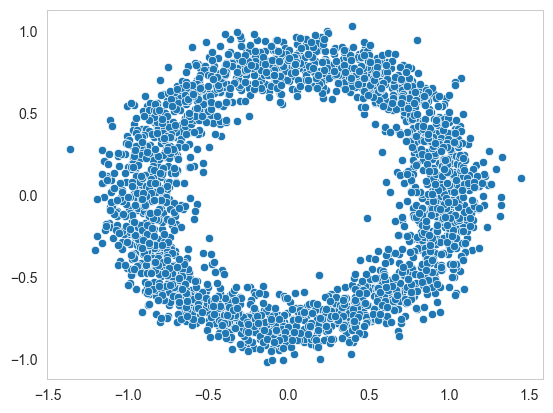

In [28]:
plt.figure()
z = z[:,74,:].reshape(-1,2)
sns.scatterplot(x=z[:,0],y=z[:,1])

In [ ]:
plt.figure()
sns.histplot(np.mean(x,axis=(0,1)))

In [ ]:
plt.figure()
sns.lineplot(pca.explained_variance_ratio_[:10],marker='.')

In [ ]:


## RESPONSE MATRIX
model_data = df[df.model_id=='F6GafsOg']
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.sigma_rec = 0.
net.sigma_in = 0.1

variance = model_data['var'].item()
u, z, mask, conditions  = generate_trials(
                            n_trials=50)
x = net(u).detach().cpu().numpy()

#activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# activity_std = torch.std(torch.mean(x, dim=[0, 1])).detach().cpu().numpy() / torch.mean(torch.mean(x, dim=[0, 1])).detach().cpu().numpy()
# 
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

responses = responses[np.mean(responses, axis=1) >.025, :]


responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]